In [1]:
import sys
import pysat

print("Python:", sys.executable)
print("PySAT version:", pysat.__version__)
print("Notebook setup successful!")

Python: /Users/adamhalaseh/ECE505-Project/.venv/bin/python
PySAT version: 1.9.dev25
Notebook setup successful!


In [2]:
import sys
import csv
import json
import time
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from openpyxl import load_workbook
from IPython.display import display

ROOT = Path.cwd()

if (ROOT / "sat_comparison").is_dir():
    ROOT = ROOT / "sat_comparison"

sys.path.insert(0, str(ROOT))

import c6288sat_find_solutions as sat6288
import c7552_find_solutions as sat7552

MAX_SOLUTIONS = 100
TIMEOUT_S = 30.0

SOLVER_NAMES = [
    "Minisat22",
    "Cadical103",
    "Cadical153",
    "Cadical195",
    "Gluecard3",
    "Gluecard4",
    "Glucose3",
    "Glucose4",
    "Glucose42",
    "Lingeling"
]

CONFIG = {
    "c6288": {
        "module": sat6288,
        "cnf": "cnf.txt",
        "nodes": "node_index.txt",
        "constraints": "c6288_constraints.csv",
        "template": "SAT.xlsx",
        "base_count": 8913,
        "constraint_count": 1624,
        "positive_count": 914,
        "negative_count": 710,
        "variable_count": 3312
    },
    "c7552": {
        "module": sat7552,
        "cnf": "cnf(1).txt",
        "nodes": "node_index(1).txt",
        "constraints": "c7552_constraints.csv",
        "template": "SAT(1).xlsx",
        "base_count": 5053,
        "constraint_count": 875,
        "positive_count": 583,
        "negative_count": 292,
        "variable_count": 2064
    }
}

print("Project folder:", ROOT)
print("Circuits:", list(CONFIG.keys()))
print("Number of SAT solvers:", len(SOLVER_NAMES))
print("Configuration successful!")

Matplotlib is building the font cache; this may take a moment.


Project folder: /Users/adamhalaseh/ECE505-Project/sat_comparison
Circuits: ['c6288', 'c7552']
Number of SAT solvers: 10
Configuration successful!


In [3]:
base_cnfs = {}

for circuit, cfg in CONFIG.items():

    sat = cfg["module"]

    clauses = sat.load_cnf(
        str(ROOT / cfg["cnf"])
    )

    assert len(clauses) == cfg["base_count"], (
        f"Incorrect CNF clause count for {circuit}"
    )

    base_cnfs[circuit] = clauses

    with sat.SOLVER_MAP["Minisat22"](
        bootstrap_with=clauses
    ) as solver:

        satisfiable = solver.solve()

    print("=" * 50)
    print("Circuit:", circuit)
    print("CNF file:", cfg["cnf"])
    print("Original CNF clauses:", len(clauses))
    print("Satisfiable:", satisfiable)

    assert satisfiable, "Original CNF is UNSAT"

print("\nOriginal CNF validation passed.")

Circuit: c6288
CNF file: cnf.txt
Original CNF clauses: 8913
Satisfiable: True
Circuit: c7552
CNF file: cnf(1).txt
Original CNF clauses: 5053
Satisfiable: True

Original CNF validation passed.


In [4]:
circuits = {}

for circuit, cfg in CONFIG.items():

    sat = cfg["module"]

    base_clauses = base_cnfs[circuit]

    with open(
        ROOT / cfg["constraints"],
        newline=""
    ) as f:

        records = list(csv.DictReader(f))

    positives = [
        int(r["sat_variable"])
        for r in records
        if r["required_value"] == "1"
    ]

    negatives = [
        int(r["sat_variable"])
        for r in records
        if r["required_value"] == "0"
    ]

    assert len(records) == cfg["constraint_count"]
    assert len(positives) == cfg["positive_count"]
    assert len(negatives) == cfg["negative_count"]

    node_records = [
        line.strip()
        for line in (
            ROOT / cfg["nodes"]
        ).read_text().splitlines()
        if "(" in line and line.strip().endswith(")")
    ]

    assert len(node_records) == cfg["variable_count"]

    for record in records:

        var = int(record["sat_variable"])

        assert 1 <= var <= len(node_records)
        assert record["required_value"] in ("0", "1")

        expected = f'WIRE({record["signal"]})'

        assert node_records[var - 1] == expected

    constraint_clauses = sat.build_constraint_clauses(
        positives,
        negatives,
        str(ROOT / cfg["nodes"])
    )

    all_clauses = base_clauses + constraint_clauses

    groups = sat.load_node_groups(
        str(ROOT / cfg["nodes"])
    )

    used_vars = {
        abs(lit)
        for clause in all_clauses
        for lit in clause
    }

    unused_vars = (
        set(range(1, cfg["variable_count"] + 1))
        - used_vars
    )

    with sat.SOLVER_MAP["Minisat22"](
        bootstrap_with=all_clauses
    ) as solver:

        satisfiable = solver.solve()

    assert satisfiable, "Constrained CNF is UNSAT"

    circuits[circuit] = {
        "base": base_clauses,
        "constraints": constraint_clauses,
        "all": all_clauses,
        "groups": groups,
        "used_vars": used_vars,
        "unused_vars": unused_vars,
        "nvars": cfg["variable_count"]
    }

    print("=" * 50)
    print("Circuit:", circuit)
    print("Inputs:", len(groups["INPUT"]))
    print("Outputs:", len(groups["OUTPUT"]))
    print("Internal wires:", len(groups["WIRE"]))
    print("Original clauses:", len(base_clauses))
    print("Positive constraints:", len(positives))
    print("Negative constraints:", len(negatives))
    print("Total constraints:", len(constraint_clauses))
    print("Final CNF clauses:", len(all_clauses))
    print("Unused indexed variables:", len(unused_vars))
    print("Constrained CNF satisfiable:", satisfiable)
    print("VALIDATION PASSED")

print("\nBoth circuits are ready for benchmarking.")

Circuit: c6288
Inputs: 32
Outputs: 32
Internal wires: 3248
Original clauses: 8913
Positive constraints: 914
Negative constraints: 710
Total constraints: 1624
Final CNF clauses: 10537
Unused indexed variables: 0
Constrained CNF satisfiable: True
VALIDATION PASSED
Circuit: c7552
Inputs: 207
Outputs: 108
Internal wires: 1749
Original clauses: 5053
Positive constraints: 583
Negative constraints: 292
Total constraints: 875
Final CNF clauses: 5928
Unused indexed variables: 55
Constrained CNF satisfiable: True
VALIDATION PASSED

Both circuits are ready for benchmarking.


In [5]:
def find_first_n_solutions(
    solver_class,
    circuit_data,
    n=MAX_SOLUTIONS,
    timeout_s=TIMEOUT_S
):

    clauses = circuit_data["all"]
    nvars = circuit_data["nvars"]
    used_vars = circuit_data["used_vars"]

    solutions = []
    status = "completed_max_n"

    start = time.perf_counter()

    with solver_class(
        bootstrap_with=clauses,
        use_timer=True
    ) as solver:

        while len(solutions) < n:

            if time.perf_counter() - start >= timeout_s:
                status = "timeout"
                break

            if not solver.solve():
                status = "completed_unsat"
                break

            raw_model = solver.get_model()

            if raw_model is None:
                raise RuntimeError("Solver returned no model")

            assignment = {
                abs(lit): lit > 0
                for lit in raw_model
                if lit != 0
            }

            assert used_vars.issubset(assignment), (
                "Incomplete SAT model"
            )

            model = tuple(
                v if assignment.get(v, False) else -v
                for v in range(1, nvars + 1)
            )

            solutions.append(model)

            # Prevent the same solution from appearing again.
            blocking_clause = [-lit for lit in model]

            solver.add_clause(blocking_clause)

        cpu_time = solver.time_accum()

    elapsed_time = time.perf_counter() - start

    return solutions, cpu_time, elapsed_time, status


print("SAT solution finder created successfully.")

SAT solution finder created successfully.


In [6]:
def verify_solutions(solutions, circuit_data):

    base = circuit_data["base"]
    constraints = circuit_data["constraints"]
    nvars = circuit_data["nvars"]

    used_vars = sorted(circuit_data["used_vars"])

    valid_base = 0
    valid_constraints = 0

    unique_count = len(set(solutions))

    for model in solutions:

        assert len(model) == nvars

        assert all(
            abs(lit) == i
            for i, lit in enumerate(model, start=1)
        )

        assignment = set(model)

        base_ok = all(
            any(lit in assignment for lit in clause)
            for clause in base
        )

        constraints_ok = all(
            any(lit in assignment for lit in clause)
            for clause in constraints
        )

        valid_base += int(base_ok)

        valid_constraints += int(constraints_ok)

    active_unique = len({
        tuple(model[v - 1] for v in used_vars)
        for model in solutions
    })

    passed = (
        len(solutions) > 0
        and valid_base == len(solutions)
        and valid_constraints == len(solutions)
        and unique_count == len(solutions)
    )

    return {
        "solutions_found": len(solutions),
        "unique_solutions": unique_count,
        "active_unique_solutions": active_unique,
        "valid_cnf": valid_base,
        "valid_constraints": valid_constraints,
        "verification": "PASS" if passed else "FAIL"
    }


print("Solution verification function ready.")

Solution verification function ready.


In [7]:
all_results = {}
all_details = {}

for circuit, cfg in CONFIG.items():

    print("\n" + "=" * 60)
    print("BENCHMARKING:", circuit)
    print("=" * 60)

    sat = cfg["module"]
    data = circuits[circuit]

    rows = []
    details = {}

    for name in SOLVER_NAMES:

        print(f"\nRunning {name}...", flush=True)

        try:

            solver_class = sat.SOLVER_MAP[name]

            solutions, cpu, elapsed, status = (
                find_first_n_solutions(
                    solver_class,
                    data
                )
            )

            verification = verify_solutions(
                solutions,
                data
            )

            row = {
                "SAT Solver": name,

                "# of Unique Solutions":
                    verification["unique_solutions"],

                "Time (s)": cpu,

                "Elapsed Time (s)": elapsed,

                "Valid CNF Solutions":
                    verification["valid_cnf"],

                "Valid Constraint Solutions":
                    verification["valid_constraints"],

                "Active Variable Solutions":
                    verification["active_unique_solutions"],

                "Verification":
                    verification["verification"],

                "Status": status
            }

            rows.append(row)

            details[name] = {
                **row,
                "solutions": [
                    "".join(
                        "1" if lit > 0 else "0"
                        for lit in model
                    )
                    for model in solutions
                ]
            }

            print("Solutions:", len(solutions))
            print(f"CPU time: {cpu:.9f} seconds")
            print(f"Elapsed time: {elapsed:.6f} seconds")
            print("Status:", status)

            print(
                "Verification:",
                verification["verification"]
            )

            print(
                "Active-variable unique solutions:",
                verification["active_unique_solutions"]
            )

            if solutions:
                print(
                    "Sample solution (first 25 variables):",
                    solutions[0][:25]
                )

        except Exception as e:

            row = {
                "SAT Solver": name,
                "# of Unique Solutions": None,
                "Time (s)": None,
                "Elapsed Time (s)": None,
                "Valid CNF Solutions": None,
                "Valid Constraint Solutions": None,
                "Active Variable Solutions": None,
                "Verification": "FAIL",
                "Status": "error"
            }

            rows.append(row)

            details[name] = {
                **row,
                "error": str(e)
            }

            print("ERROR:", e)

    all_results[circuit] = pd.DataFrame(rows)
    all_details[circuit] = details

    print(f"\nFINAL RESULTS: {circuit}")

    display(all_results[circuit])

print("\nBenchmarking completed.")


BENCHMARKING: c6288

Running Minisat22...
Solutions: 100
CPU time: 0.018122000 seconds
Elapsed time: 0.127744 seconds
Status: completed_max_n
Verification: PASS
Active-variable unique solutions: 100
Sample solution (first 25 variables): (1, -2, -3, -4, -5, -6, -7, -8, -9, -10, -11, -12, -13, -14, -15, -16, 17, 18, -19, -20, -21, -22, -23, -24, -25)

Running Cadical103...
Solutions: 100
CPU time: 0.027878000 seconds
Elapsed time: 0.095780 seconds
Status: completed_max_n
Verification: PASS
Active-variable unique solutions: 100
Sample solution (first 25 variables): (1, 2, 3, 4, 5, 6, 7, 8, -9, -10, -11, -12, -13, -14, -15, -16, 17, 18, 19, 20, 21, 22, 23, 24, 25)

Running Cadical153...
Solutions: 100
CPU time: 0.027876000 seconds
Elapsed time: 0.096198 seconds
Status: completed_max_n
Verification: PASS
Active-variable unique solutions: 100
Sample solution (first 25 variables): (1, 2, 3, 4, 5, 6, 7, 8, -9, -10, -11, -12, -13, -14, -15, -16, 17, 18, 19, 20, 21, 22, 23, 24, 25)

Running Cad

,SAT Solver,# of Unique Solutions,Time (s),Elapsed Time (s),Valid CNF Solutions,Valid Constraint Solutions,Active Variable Solutions,Verification,Status
0,Minisat22,100,0.018122,0.127744,100,100,100,PASS,completed_max_n
1,Cadical103,100,0.027878,0.095780,100,100,100,PASS,completed_max_n
2,Cadical153,100,0.027876,0.096198,100,100,100,PASS,completed_max_n
3,Cadical195,100,0.012115,0.083311,100,100,100,PASS,completed_max_n
4,Gluecard3,100,0.015389,0.079036,100,100,100,PASS,completed_max_n
5,Gluecard4,100,0.015035,0.078159,100,100,100,PASS,completed_max_n
6,Glucose3,100,0.015410,0.078257,100,100,100,PASS,completed_max_n
7,Glucose4,100,0.015259,0.077504,100,100,100,PASS,completed_max_n
8,Glucose42,100,0.014969,0.077411,100,100,100,PASS,completed_max_n
9,Lingeling,100,1.997418,2.106501,100,100,100,PASS,completed_max_n



BENCHMARKING: c7552

Running Minisat22...
Solutions: 100
CPU time: 0.003351000 seconds
Elapsed time: 0.046148 seconds
Status: completed_max_n
Verification: PASS
Active-variable unique solutions: 62
Sample solution (first 25 variables): (-1, 2, -3, 4, 5, -6, 7, 8, -9, -10, -11, -12, -13, -14, -15, -16, -17, -18, -19, -20, -21, -22, -23, -24, -25)

Running Cadical103...
Solutions: 100
CPU time: 0.021012000 seconds
Elapsed time: 0.061501 seconds
Status: completed_max_n
Verification: PASS
Active-variable unique solutions: 98
Sample solution (first 25 variables): (1, 2, -3, 4, 5, -6, 7, 8, 9, -10, -11, -12, 13, 14, -15, -16, 17, 18, 19, 20, 21, 22, 23, 24, 25)

Running Cadical153...
Solutions: 100
CPU time: 0.020941000 seconds
Elapsed time: 0.062368 seconds
Status: completed_max_n
Verification: PASS
Active-variable unique solutions: 98
Sample solution (first 25 variables): (1, 2, -3, 4, 5, -6, 7, 8, 9, -10, -11, -12, 13, 14, -15, -16, 17, 18, 19, 20, 21, 22, 23, 24, 25)

Running Cadical195

,SAT Solver,# of Unique Solutions,Time (s),Elapsed Time (s),Valid CNF Solutions,Valid Constraint Solutions,Active Variable Solutions,Verification,Status
0,Minisat22,100,0.003351,0.046148,100,100,62,PASS,completed_max_n
1,Cadical103,100,0.021012,0.061501,100,100,98,PASS,completed_max_n
2,Cadical153,100,0.020941,0.062368,100,100,98,PASS,completed_max_n
3,Cadical195,100,0.003659,0.045563,100,100,48,PASS,completed_max_n
4,Gluecard3,100,0.003203,0.043419,100,100,62,PASS,completed_max_n
5,Gluecard4,100,0.003001,0.042674,100,100,62,PASS,completed_max_n
6,Glucose3,100,0.002944,0.041642,100,100,62,PASS,completed_max_n
7,Glucose4,100,0.002872,0.041697,100,100,62,PASS,completed_max_n
8,Glucose42,100,0.002830,0.041534,100,100,62,PASS,completed_max_n
9,Lingeling,100,0.028054,0.092197,100,100,71,PASS,completed_max_n



Benchmarking completed.


In [8]:
from openpyxl.comments import Comment

RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

for circuit, df in all_results.items():

    assert len(df) == 10
    assert (df["Verification"] == "PASS").all()

    output_dir = RESULTS_DIR / circuit
    output_dir.mkdir(exist_ok=True)

    template = ROOT / CONFIG[circuit]["template"]

    wb = load_workbook(template)
    ws = wb.active

    expected_headers = [
        "SAT Solver",
        "# of Unique Solutions",
        "Time (s)"
    ]

    assert [
        ws.cell(1, col).value
        for col in range(1, 4)
    ] == expected_headers

    for excel_row, record in enumerate(
        df.to_dict("records"),
        start=2
    ):

        ws.cell(
            excel_row,
            1,
            record["SAT Solver"]
            
        )

        count = int(
            record["# of Unique Solutions"]
        )

        if record["Status"] == "timeout":
            count = f"{count} (timeout)"

        ws.cell(excel_row, 2, count)

        time_cell = ws.cell(
            excel_row,
            3,
            float(record["Time (s)"])
        )

        time_cell.number_format = "0.000000"

    ws["B1"].comment = Comment(
        "Number of unique full assignments found. "
        "Search limited to 100 solutions per solver.",
        "ECE505"
    )

    ws["C1"].comment = Comment(
        "Cumulative SAT solver CPU time in seconds.",
        "ECE505"
    )

    if circuit == "c7552":

        ws["B1"].comment = Comment(
            "Full-assignment uniqueness, capped at 100. "
            "The supplied constrained CNF has 55 unused "
            "indexed variables. See the comparison CSV "
            "for active-variable uniqueness.",
            "ECE505"
        )

    output_file = output_dir / "SAT.xlsx"

    wb.save(output_file)

    df.to_csv(
        output_dir / "solver_comparison.csv",
        index=False
    )

    payload = {
        "circuit": circuit,
        "max_solutions": MAX_SOLUTIONS,
        "timeout_seconds": TIMEOUT_S,
        "timing_method": "Cumulative solver CPU time",
        "uniqueness": "Complete indexed assignments",
        "unused_variables": sorted(
            circuits[circuit]["unused_vars"]
        ),
        "solution_encoding":
            "Bit position i-1 corresponds to variable i",
        "solvers": all_details[circuit]
    }

    with open(
        output_dir / "benchmark_raw.json",
        "w"
    ) as f:

        json.dump(payload, f, indent=2)

    print("Excel saved:", output_file)

print("\nBoth SAT.xlsx files generated successfully.")

Excel saved: /Users/adamhalaseh/ECE505-Project/sat_comparison/results/c6288/SAT.xlsx
Excel saved: /Users/adamhalaseh/ECE505-Project/sat_comparison/results/c7552/SAT.xlsx

Both SAT.xlsx files generated successfully.



PERFORMANCE COMPARISON: c6288
Verified solvers: 10 / 10

Fastest solver: Cadical195
CPU time: 0.012115 s

Slowest solver: Lingeling
CPU time: 1.997418 s


,SAT Solver,# of Unique Solutions,Time (s),Verification
3,Cadical195,100,0.012115,PASS
8,Glucose42,100,0.014969,PASS
5,Gluecard4,100,0.015035,PASS
7,Glucose4,100,0.015259,PASS
4,Gluecard3,100,0.015389,PASS
6,Glucose3,100,0.015410,PASS
0,Minisat22,100,0.018122,PASS
2,Cadical153,100,0.027876,PASS
1,Cadical103,100,0.027878,PASS
9,Lingeling,100,1.997418,PASS


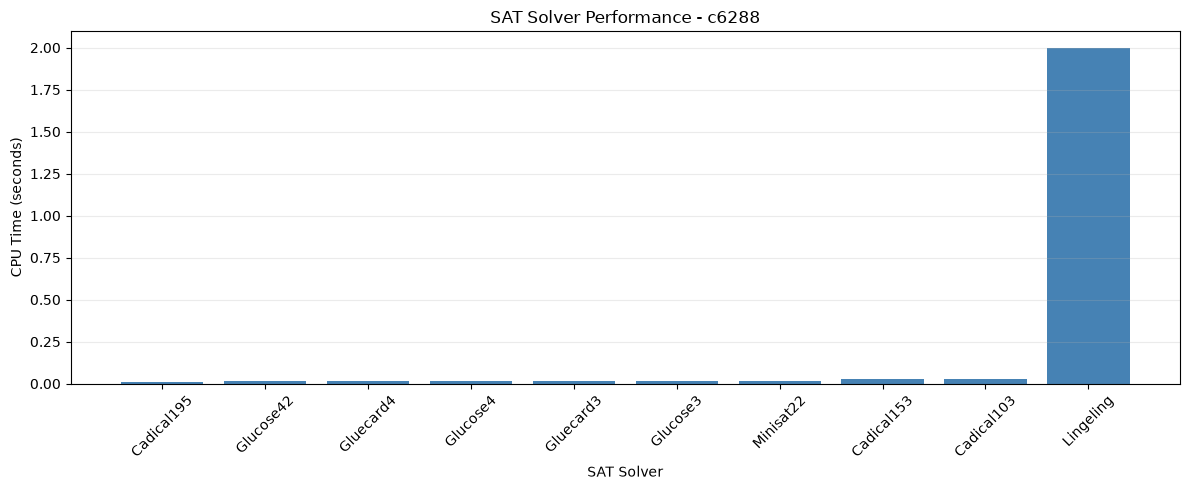


PERFORMANCE COMPARISON: c7552
Verified solvers: 10 / 10

Fastest solver: Glucose42
CPU time: 0.002830 s

Slowest solver: Lingeling
CPU time: 0.028054 s


,SAT Solver,# of Unique Solutions,Time (s),Verification
8,Glucose42,100,0.002830,PASS
7,Glucose4,100,0.002872,PASS
6,Glucose3,100,0.002944,PASS
5,Gluecard4,100,0.003001,PASS
4,Gluecard3,100,0.003203,PASS
0,Minisat22,100,0.003351,PASS
3,Cadical195,100,0.003659,PASS
2,Cadical153,100,0.020941,PASS
1,Cadical103,100,0.021012,PASS
9,Lingeling,100,0.028054,PASS


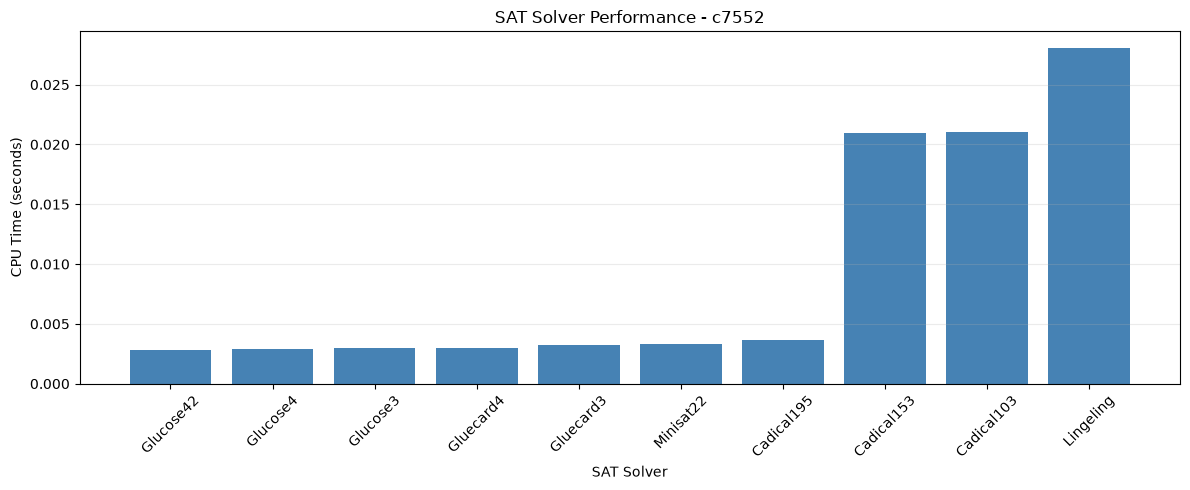

In [9]:
for circuit, df in all_results.items():

    print("\n" + "=" * 60)
    print("PERFORMANCE COMPARISON:", circuit)
    print("=" * 60)

    comparable = df[
        (df["Verification"] == "PASS")
        & (df["Status"] == "completed_max_n")
        & (df["# of Unique Solutions"] == MAX_SOLUTIONS)
    ].copy()

    comparable = comparable.sort_values("Time (s)")

    if comparable.empty:
        print("No comparable completed runs.")
        continue

    fastest = comparable.iloc[0]
    slowest = comparable.iloc[-1]

    print(
        "Verified solvers:",
        (df["Verification"] == "PASS").sum(),
        "/ 10"
    )

    print("\nFastest solver:", fastest["SAT Solver"])
    print(f'CPU time: {fastest["Time (s)"]:.6f} s')

    print("\nSlowest solver:", slowest["SAT Solver"])
    print(f'CPU time: {slowest["Time (s)"]:.6f} s')

    display(
        comparable[
            [
                "SAT Solver",
                "# of Unique Solutions",
                "Time (s)",
                "Verification"
            ]
        ]
    )

    plt.figure(figsize=(12, 5))

    plt.bar(
        comparable["SAT Solver"],
        comparable["Time (s)"],
        color="steelblue"
    )

    plt.xlabel("SAT Solver")
    plt.ylabel("CPU Time (seconds)")
    plt.title(f"SAT Solver Performance - {circuit}")

    plt.xticks(rotation=45)
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        RESULTS_DIR
        / circuit
        / "solver_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [10]:
project_passed = True

for circuit, df in all_results.items():

    print("\n" + "=" * 50)
    print("FINAL VERIFICATION:", circuit)
    print("=" * 50)

    solver_count = len(df)

    verified_count = int(
        (df["Verification"] == "PASS").sum()
    )

    completed_count = int(
        (df["Status"] == "completed_max_n").sum()
    )

    excel_file = (
        RESULTS_DIR / circuit / "SAT.xlsx"
    )

    wb = load_workbook(excel_file)
    ws = wb.active

    excel_correct = True

    for row_number, record in enumerate(
        df.to_dict("records"),
        start=2
    ):

        assert ws.cell(row_number, 1).value == (
            record["SAT Solver"]
        )

        assert ws.cell(row_number, 2).value == int(
            record["# of Unique Solutions"]
        )

        assert abs(
            ws.cell(row_number, 3).value
            - float(record["Time (s)"])
        ) < 1e-12

    passed = (
        solver_count == 10
        and verified_count == 10
        and completed_count == 10
        and excel_correct
    )

    print("Solvers executed:", solver_count, "/ 10")
    print("Verification passed:", verified_count, "/ 10")
    print("Reached 100 solutions:", completed_count, "/ 10")
    print("Excel results match benchmark:", excel_correct)

    if passed:
        print("CIRCUIT STATUS: PASS")
    else:
        project_passed = False
        print("CIRCUIT STATUS: REVIEW REQUIRED")

print("\n" + "=" * 50)

if project_passed:
    print("PROJECT COMPLETED SUCCESSFULLY")
else:
    print("PROJECT REQUIRES REVIEW")


FINAL VERIFICATION: c6288
Solvers executed: 10 / 10
Verification passed: 10 / 10
Reached 100 solutions: 10 / 10
Excel results match benchmark: True
CIRCUIT STATUS: PASS

FINAL VERIFICATION: c7552
Solvers executed: 10 / 10
Verification passed: 10 / 10
Reached 100 solutions: 10 / 10
Excel results match benchmark: True
CIRCUIT STATUS: PASS

PROJECT COMPLETED SUCCESSFULLY


START_TEXT Conclusions

This study evaluated and compared the performance of ten different SAT solvers in solving two benchmark digital circuits with added wire constraint specifications.

c6288 Results

• Number of original CNF clauses = 8,913
• Number of additional wire constraints = 1,624
• Number of total CNF clauses = 10,537
• Ten different SAT solvers produced one hundred unique assignment(s) for c6288.
• Each produced assignment(s) satisfied both the original CNF and the additional constraints.
• The fastest SAT solver = Cadical195 (0.012115 second(s))
• The slowest SAT solver = Lingeling (1.997418 second(s))

c7552 Results

• Number of original CNF clauses = 5,053
• Number of additional wire constraints = 875
• Number of total CNF clauses = 5,928
• Ten different SAT solvers produced one hundred unique assignment(s) for c7552.
• Each produced assignment(s) satisfied both the original CNF and the additional constraints.
• The fastest SAT solver = Glucose42 (0.002830 second(s))
• The slowest SAT solver = Lingeling (0.028054 second(s))

Discussion

All ten SAT solvers produced the required number of solutions as needed; however, they produced them at different CPU execution times. For example, Cadical195 proved to be the most efficient solver for c6288. On the other hand, Glucose42 was the most efficient solver for c7552. In addition, Lingeling had the longest CPU execution time for both c7552 and c7552.

In terms of variable indexing, there were fifty-five unused indexed variables included in the c7552 constrained CNF. Therefore, when producing some unique full assignments for c7552, the only difference was in the unconstrained variables. Hence, active-variable uniqueness was tracked separately due to this limitation.

To conduct the experiments, Python version 3.13.1 and PySAT version 1.9.dev25 were used. A Jupyter Notebook within Visual Studio Code was utilized as the environment. To cap off each solver's run, each solver was limited to finding one hundred unique assignments. Additionally, to track how much time it took to find these assignments, cumulative solver CPU time was recorded.

Therefore, as illustrated by the results from this study, it is clear that the performance of SAT solvers varies depending on the specific circuit being solved and its constraints. All produced assignments were successfully validated. The results are available in the corresponding SAT.xlsx file. This study represents a capped single run benchmark and does not represent an exhaustive enumeration nor an absolute ranking of SAT solvers.